# TRAIN THIS DATA
---


In [206]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as  plt
import os 
df1 = pd.read_csv("train.csv",index_col=0)#index_col to remove the default indexing and giving the new one
df2 = pd.read_csv("test.csv",index_col=0)
# print(f'df1.shape=>{df1.head()}')
# print(f'df2.shape=>{df2.head()}')
# print(df1.info())
print(df1.describe(include='all'))

if "SalePrice" not in df2.columns:
    df2['SalePrice']=0
df = pd.concat(
    [df1,df2],
    axis=0,
 )
print(f'df.shape=> {df.shape}')
df.head()


         MSSubClass MSZoning  LotFrontage        LotArea Street Alley  \
count   1460.000000     1460  1201.000000    1460.000000   1460    91   
unique          NaN        5          NaN            NaN      2     2   
top             NaN       RL          NaN            NaN   Pave  Grvl   
freq            NaN     1151          NaN            NaN   1454    50   
mean      56.897260      NaN    70.049958   10516.828082    NaN   NaN   
std       42.300571      NaN    24.284752    9981.264932    NaN   NaN   
min       20.000000      NaN    21.000000    1300.000000    NaN   NaN   
25%       20.000000      NaN    59.000000    7553.500000    NaN   NaN   
50%       50.000000      NaN    69.000000    9478.500000    NaN   NaN   
75%       70.000000      NaN    80.000000   11601.500000    NaN   NaN   
max      190.000000      NaN   313.000000  215245.000000    NaN   NaN   

       LotShape LandContour Utilities LotConfig  ...     PoolArea PoolQC  \
count      1460        1460      1460      1460

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [207]:
df_null =df[df.isnull().sum()[df.isnull().sum()>0].index]
df_null.head()
# for i in df_null.columns:
#     print(f'"{i}"        =>{df[f"{i}"].isnull().sum()}')
# null_cols = df.columns[df.isnull().sum() > 0]
# df_null = df[null_cols]
#df[df['MSZoning'].isnull()==True] to get the specific column with containing null
# for i in range(len(df)):
#     print(f'{df.iloc[[i],0:3]}\t ......=> {df.iloc[i].isnull().sum()}')
# for i in df.index:
#     print(f'{df.iloc[i]}        =>{df.loc[i].isnull().sum()}')


,MSZoning,LotFrontage,Alley,Utilities,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,BsmtQual,BsmtCond,...,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PoolQC,Fence,MiscFeature,SaleType
Id,,,,,,,,,,,,,,,,,,,,,
1,RL,65.0,NaN,AllPub,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,...,2003.0,RFn,2.0,548.0,TA,TA,NaN,NaN,NaN,WD
2,RL,80.0,NaN,AllPub,MetalSd,MetalSd,NaN,0.0,Gd,TA,...,1976.0,RFn,2.0,460.0,TA,TA,NaN,NaN,NaN,WD
3,RL,68.0,NaN,AllPub,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,...,2001.0,RFn,2.0,608.0,TA,TA,NaN,NaN,NaN,WD
4,RL,60.0,NaN,AllPub,Wd Sdng,Wd Shng,NaN,0.0,TA,Gd,...,1998.0,Unf,3.0,642.0,TA,TA,NaN,NaN,NaN,WD
5,RL,84.0,NaN,AllPub,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,...,2000.0,RFn,3.0,836.0,TA,TA,NaN,NaN,NaN,WD


(2919, 34)


<Axes: xlabel='SalePrice', ylabel='Id'>

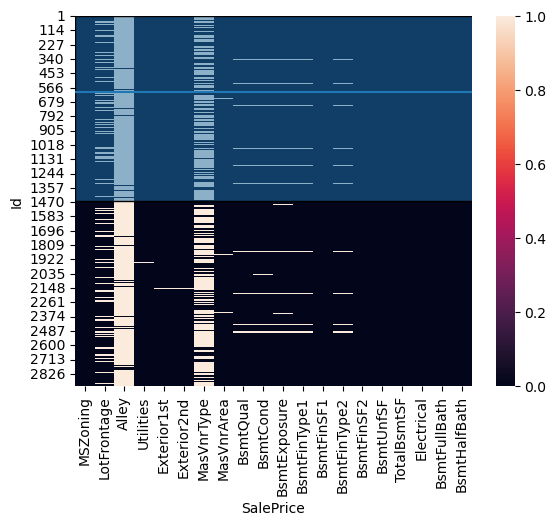

In [208]:
print(df_null.shape)
sns.heatmap(df_null.loc[:,df_null.columns[0:20]].isnull())
sns.histplot(df['SalePrice'], kde=True)

In [209]:
df_objects = df[df.select_dtypes(include='object').columns]
# print(df_objects.shape)#(2919, 43)
df_objects_nan_arr=df_objects.isna().sum()[df_objects.isna().sum()>1100].index
# print(df[df_objects_nan_arr].isna().sum())
# print(df[df_objects_nan_arr])
# df_objects[df_objects_nan_arr]
# df_objects.drop(columns=df_objects_nan_arr).shape
# print(df_objects.shape)#includes all the object ones 
# print(df_objects[df_objects_nan_arr].shape)#arr of columns having more than 1100 nan sum
# print(df_objects.drop(columns=df_objects_nan_arr).shape)#removing these columns 
df= df.drop(columns=df_objects_nan_arr)#6 columns removed from the original
df

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,...,0,0,0,0,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,272,0,0,0,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,...,0,0,0,0,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2915,160,RM,21.0,1936,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,6,2006,WD,Normal,0
2916,160,RM,21.0,1894,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,4,2006,WD,Abnorml,0
2917,20,RL,160.0,20000,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,0,0,9,2006,WD,Abnorml,0


In [210]:
df_objects_new = df_objects.drop(columns=df_objects_nan_arr)
print(df_objects.shape)
print(df_objects_new.shape)
df_objects_new = df_objects_new.fillna('null')
df_objects_encoded= pd.get_dummies(df_objects_new,dtype=int)
print(df_objects_encoded.shape)
# df_objects_new['MSZoning'].value_counts()
df_encoded_col_value_check =0
for cols in df_objects_new.columns:
    print(f'\033[35m{df_objects_new[cols].nunique()}\033[0m\t\n\033[33m{df_objects_new[cols].value_counts()}\033[0m\n\n')
    df_encoded_col_value_check +=df_objects_new[cols].nunique()
print(df_encoded_col_value_check)

(2919, 43)
(2919, 37)
(2919, 247)
6	
MSZoning
RL         2265
RM          460
FV          139
RH           26
C (all)      25
null          4
Name: count, dtype: int64


2	
Street
Pave    2907
Grvl      12
Name: count, dtype: int64


4	
LotShape
Reg    1859
IR1     968
IR2      76
IR3      16
Name: count, dtype: int64


4	
LandContour
Lvl    2622
HLS     120
Bnk     117
Low      60
Name: count, dtype: int64


3	
Utilities
AllPub    2916
null         2
NoSeWa       1
Name: count, dtype: int64


5	
LotConfig
Inside     2133
Corner      511
CulDSac     176
FR2          85
FR3          14
Name: count, dtype: int64


3	
LandSlope
Gtl    2778
Mod     125
Sev      16
Name: count, dtype: int64


25	
Neighborhood
NAmes      443
CollgCr    267
OldTown    239
Edwards    194
Somerst    182
NridgHt    166
Gilbert    165
Sawyer     151
NWAmes     131
SawyerW    125
Mitchel    114
BrkSide    108
Crawfor    103
IDOTRR      93
Timber      72
NoRidge     71
StoneBr     51
SWISU       48
ClearCr     44
M

In [211]:
df_objects_encoded.head()

,MSZoning_C (all),MSZoning_FV,MSZoning_RH,MSZoning_RL,MSZoning_RM,MSZoning_null,Street_Grvl,Street_Pave,LotShape_IR1,LotShape_IR2,...,SaleType_New,SaleType_Oth,SaleType_WD,SaleType_null,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
Id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,1,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0
3,0,0,0,1,0,0,0,1,1,0,...,0,0,1,0,0,0,0,0,1,0
4,0,0,0,1,0,0,0,1,1,0,...,0,0,1,0,1,0,0,0,0,0
5,0,0,0,1,0,0,0,1,1,0,...,0,0,1,0,0,0,0,0,1,0


In [212]:
# sns.heatmap(df_objects.loc[:, df_objects.columns[:20]].isnull())
# plt.title("df_objects (old ones)", fontsize=16)
# sns.heatmap(df_objects_new.loc[:, df_objects_new.columns[:20]].isnull())
# plt.title("df_objects_new",fontdict={"color":"darkblue"}, fontsize=16)

In [213]:
drop_null_cols = [cols for cols in df_objects_encoded if 'null' in cols]
df_objects_encoded = df_objects_encoded.drop(columns=drop_null_cols)
df_objects_encoded.columns

Index(['MSZoning_C (all)', 'MSZoning_FV', 'MSZoning_RH', 'MSZoning_RL',
       'MSZoning_RM', 'Street_Grvl', 'Street_Pave', 'LotShape_IR1',
       'LotShape_IR2', 'LotShape_IR3',
       ...
       'SaleType_ConLw', 'SaleType_New', 'SaleType_Oth', 'SaleType_WD',
       'SaleCondition_Abnorml', 'SaleCondition_AdjLand',
       'SaleCondition_Alloca', 'SaleCondition_Family', 'SaleCondition_Normal',
       'SaleCondition_Partial'],
      dtype='object', length=230)

In [214]:
new_df = pd.concat([df,df_objects_encoded],axis=1)
print(len(new_df.columns))
new_df.head()

304


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,...,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,Reg,Lvl,AllPub,Inside,Gtl,...,0,0,0,1,0,0,0,0,1,0
2,20,RL,80.0,9600,Pave,Reg,Lvl,AllPub,FR2,Gtl,...,0,0,0,1,0,0,0,0,1,0
3,60,RL,68.0,11250,Pave,IR1,Lvl,AllPub,Inside,Gtl,...,0,0,0,1,0,0,0,0,1,0
4,70,RL,60.0,9550,Pave,IR1,Lvl,AllPub,Corner,Gtl,...,0,0,0,1,1,0,0,0,0,0
5,60,RL,84.0,14260,Pave,IR1,Lvl,AllPub,FR2,Gtl,...,0,0,0,1,0,0,0,0,1,0


In [215]:
new_df = new_df.drop(df.select_dtypes(include=['object']),axis=1)
check = new_df.isna().sum()[new_df.isna().sum()>0].index
# sns.heatmap(new_df.loc[:, new_df.columns[:10]].isna())
print(new_df.info())


<class 'pandas.core.frame.DataFrame'>
Index: 2919 entries, 1 to 2919
Columns: 267 entries, MSSubClass to SaleCondition_Partial
dtypes: float64(11), int64(256)
memory usage: 6.0 MB
None


In [216]:
for dfs in check:
    if new_df[dfs].skew()>1 or new_df[dfs].skew()<-1:
        print(f'\033[33m{dfs}\033[0m  =>  \033[32m{new_df[dfs].skew()}\033[0m')
    else:
        print(f'{dfs}\033[0m  =>  {new_df[dfs].skew()}')
# print(new_df['3SsnPorch'].isnull().sum())
grouptby_median = [ dfs for dfs in check if new_df[dfs].skew()>1]

LotFrontage  =>  1.5032778146412304
MasVnrArea  =>  2.6025885122682517
BsmtFinSF1  =>  1.425722287785458
BsmtFinSF2  =>  4.1474557017396885
BsmtUnfSF  =>  0.9198236977423032
TotalBsmtSF  =>  1.1628824745982715
BsmtFullBath  =>  0.6240621985365326
BsmtHalfBath  =>  3.9320182078879196
GarageYrBlt  =>  -0.38215016096981613
GarageCars  =>  -0.21837276655710502
GarageArea  =>  0.24130051733383068


In [217]:
# """Representation of right big skew,deviated the mean from zero to 0.6 because of 4 value out of 2742"""
# print(new_df['BsmtHalfBath'].mean())
# print(new_df['BsmtHalfBath'].median())
# print("this is lenght of \033[33mvalue bigger than one =>\033[0m",len(new_df[new_df['BsmtHalfBath']>1.0].index))
# print("this is \033[33mexactly equal to zero =>\033[0m",len(new_df[new_df['BsmtHalfBath']==0.0].index))
# print(new_df['BsmtHalfBath'].mode()[0])
# # print(new_df['BsmtHalfBath'].count())
# sns.histplot(df['LotFrontage'], kde=True)
# sns.boxplot(x='MSZoning', y='LotFrontage', data=df)
"""Categorical and Numerical DATA"""
print(len(new_df.columns))
for col in new_df.columns:
    if (null_val:=int(new_df[col].isna().sum())) >0 :
        print(null_val,col)
        # sns.heatmap(new_df[col].isna())
    new_df[col] = new_df[col].fillna(new_df[col].median())
skewed_cols = new_df[new_df.columns].skew()
skewed_cols = skewed_cols[skewed_cols > 1].index
for col in skewed_cols:
    new_df[col] = np.log1p(new_df[col])

# sns.heatmap(new_df.isnull())

267
486 LotFrontage
23 MasVnrArea
1 BsmtFinSF1
1 BsmtFinSF2
1 BsmtUnfSF
1 TotalBsmtSF
2 BsmtFullBath
2 BsmtHalfBath
159 GarageYrBlt


1 GarageCars
1 GarageArea


In [218]:
train_df = new_df[new_df['SalePrice'] > 0]
test_df = new_df[new_df['SalePrice'] == 0]

In [219]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
# from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [220]:

# from sklearn.model_selection import train_test_split
# from sklearn.metrics import mean_squared_error
# from sklearn.linear_model import LinearRegression
# # from xgboost import XGBRegressor
# from sklearn.ensemble import RandomForestRegressor

# data=[
#     {'Apple':'30','Bananas':'40'},
#     {'Apple':'30','Bananas':'40'}
# ]
# cols=['2104 sales price','2104 sales price']
# fruits= pd.DataFrame(data,index=cols)
# fruits


In [221]:
# ages = pd.Series([25, 30, 35])
# print(ages)
# # Creating a DataFrame using Series
# names = pd.Series(['John', 'Alice', 'Bob'])
# cities = pd.Series(["New York", 'Los Angeles', 'Chicago'])
# print(names)
# print(cities)
# df = pd.DataFrame({
# 'Age': ages,
# 'Name': names,
# 'City': cities,
# })

# df.sort_values('Age')

# df['City'] = ['Delhi', 'Mumbai', 'Lucknow']
# df.insert(0,'Cities',['Delhi', 'Mumbai', 'Lucknow'])
# df['country']='null'

# new_row = pd.DataFrame([{'Name': 'Aman', 'Age': 22, 'City': 'Delhi'}])
# print("\n\n")
# df=pd.concat([new_row,df],ignore_index=False)
# df['Age'] = df['Age'].replace(30, 99)
# df